# ☀️ SunCedar Solar · Custom ReAct Agent with Configurable Personas
**EECE 503P/798S · C4: Agent Personas & Thinking Mechanisms** · Ahmad Jouni

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmadjouni1/AhmadJouni-ReActAgent-C4/blob/main/business_react_agent.ipynb)

This notebook turns the C3 SunCedar Solar business chatbot into a **ReAct agent** that reasons and acts through tools.
The ReAct loop is written by hand as a **LangGraph `StateGraph`** (no prebuilt agent or executor). The model writes
`Thought / Action / Final Answer` as plain text; our code parses the Action, runs the tool, feeds back an
`Observation`, and loops. Three **personas** (prompt traits + their own LLM configuration) share one **instructions
block** and four **tools**, and a logged experiment grid compares personas, LLM settings and prompt-engineering choices.

```
                    ┌────────────────────────── LangGraph StateGraph ──────────────────────────┐
 user message ──►   │  think (LLM) ──► parse ──┬─ Action ─────► act (run tool) ──► Observation ─┐ │
 + persona          │       ▲                  │                                                │ │
 + chat history     │       └──────────────────┼──────────────────────────────────────────────── ┘ │
                    │                          ├─ malformed ──► reprompt (format reminder, once)  │
                    │                          ├─ Final Answer ──► answer ──► END                 │
                    │                          └─ max steps / still malformed ──► give_up ──► END │
                    └──────────────────────────────────────────────────────────────────────────────┘
 tools: search_docs (BM25 over me/ docs) · recommend_package · record_customer_interest · record_feedback
```

| § | Section | Assignment item |
|---|---|---|
| 1 | Use case | 2.1 use-case summary |
| 2 | LLM setup & parameter support | 2.3 configurations (what the API actually honors) |
| 3 | Knowledge base & tools | 2.1 tools |
| 4 | Personas | 2.3 personas = prompt traits + LLM config |
| 5 | Instructions block | 2.4 clear instructions |
| 6 | ReAct loop in LangGraph | 2.2 manual ReAct logic |
| 7–8 | Experiments & results | 2.3 experiments, logged and compared |
| 9 | Reflection | 2.5 reflection questions |
| 10 | Gradio app | working assistant |

> Code cells are generated from `app.py` and `experiments.py` (see `scripts/build_notebook.py`). Every LLM response is
> cached in `cache/llm_cache.jsonl`, so re-running this notebook reproduces the results without spending API quota.

## 0 · Setup
**Locally:** `pip install -r requirements.txt`, then put your key in `.env` as `GEMINI_API_KEY=...`.
**Google Colab:** add `GEMINI_API_KEY` in the 🔑 *Secrets* panel (enable *Notebook access*); the next cell clones the
repo (documents, cache and results), installs the requirements and loads the key. Locally it does nothing.

In [1]:
# Google Colab only: fetch the project files, install dependencies, load the key from Colab Secrets.
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("me"):
        if os.path.exists("AhmadJouni-ReActAgent-C4"):
            !git -C AhmadJouni-ReActAgent-C4 pull -q
        else:
            !git clone -q https://github.com/ahmadjouni1/AhmadJouni-ReActAgent-C4.git
        %cd AhmadJouni-ReActAgent-C4
    %pip install -q -r requirements.txt
    from google.colab import userdata
    os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
    print("Colab setup done:", os.getcwd())

In [2]:
import ast
import hashlib
import json
import math
import os
import re
import time
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from typing import TypedDict

from dotenv import load_dotenv
from google import genai
from google.genai import errors as genai_errors
from google.genai import types
from pypdf import PdfReader

load_dotenv(override=True)

# ---- Configuration (models live here only) -------------------------------------------
# gemini-3.1-flash-lite is the agent model because it is the current model that actually honors the
# sampling parameters the personas depend on (verified in section 3.1), and it has 500 free requests/day.
AGENT_MODEL = os.getenv("GEMINI_AGENT_MODEL", "gemini-3.1-flash-lite")
JUDGE_MODEL = os.getenv("GEMINI_JUDGE_MODEL", "gemini-3.5-flash-lite")      # LLM-as-judge in the experiments
COMPARISON_MODELS = ["gemini-3.5-flash-lite", "gemini-3.8-flash"]          # "model type" experiment
APP_FALLBACK_MODELS = ["gemini-3.5-flash-lite"]                             # live chat only, if quota runs out
RPM = {"gemini-3.1-flash-lite": 15, "gemini-3.5-flash-lite": 15, "gemini-3.8-flash": 5, "gemini-3.6-flash": 5}

MAX_STEPS = 6            # max LLM calls per user message
MAX_FORMAT_RETRIES = 1   # re-prompt once when the output does not follow the ReAct format

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DOCS_DIR = ROOT / "me"
CACHE_FILE = ROOT / "cache" / "llm_cache.jsonl"
LOG_DIR = Path(os.getenv("LOG_DIR", ROOT))

api_key = os.getenv("GEMINI_API_KEY")
if not api_key:
    raise RuntimeError("GEMINI_API_KEY is not set. Put it in .env (local), Colab Secrets, or the Space secrets.")
client = genai.Client(api_key=api_key, http_options=types.HttpOptions(timeout=60_000))
print(f"Agent model: {AGENT_MODEL} | judge: {JUDGE_MODEL} | SDK: google-genai")

Agent model: gemini-3.1-flash-lite | judge: gemini-3.5-flash-lite | SDK: google-genai


## 1 · Use case
**SunCedar Solar** (fictional, reused from C3) designs and installs home solar systems in Lebanon.

| | |
|---|---|
| **Agent goal** | Help visitors understand SunCedar's packages, prices, warranty, payment options and service areas; recommend the right package for their home; capture leads (name + email) for a free site visit; log complaints and questions the documents can't answer. |
| **Target audience** | Lebanese homeowners and families tired of short EDL (state grid) hours and expensive generator subscriptions (*ishtirak*), writing in English, Arabic or Arabizi. Mostly non-technical; some want exact specs. |
| **Tools** | `search_docs` (BM25 search over the company profile PDF + summary), `recommend_package` (deterministic sizing calculator), `record_customer_interest` (lead logging), `record_feedback` (unanswered questions & complaints). |
| **Constraints** | Facts only from `me/about_business.pdf` and `me/business_summary.txt`, retrieved through `search_docs` (the documents are **not** pasted into the prompt); never invent prices, specs, discounts or policies; leads need both name and email; replies in the user's language. |
| **Limitations** | Keyword search misses synonyms and Arabizi terms (the agent must translate queries to English keywords); `recommend_package` uses simple rules, the final price is set after a site visit; no real booking system; free-tier quota (Flash-Lite 500 requests/day, Flash 20/day); temperature/top-p only work on some models (§2). |

## 2 · LLM setup and parameter support
We use Gemini through the **native `google-genai` SDK**, so every sampling parameter can be set. `generate()` adds three
things around `client.models.generate_content`: a **disk cache** keyed by model + system prompt + messages + config,
**rate limiting** per model (free-tier RPM), and retries on 429/503. Parameters the API rejects are dropped with a warning.

In [3]:
class QuotaExhausted(RuntimeError):
    """The model's daily free-tier quota is used up."""


class ParamRejected(ValueError):
    """The API rejected a generation parameter for this model (HTTP 400)."""


class ServiceUnavailable(RuntimeError):
    """The model kept answering 503/504 (overloaded) after all retries."""


# Verified in section 3.1: every current Gemini model answers HTTP 400 "Penalty is not enabled for this model".
REJECTED_PARAMS = {"presence_penalty", "frequency_penalty"}
_warned = set()


def build_config(model: str, config: dict, system: str | None, stop: list[str] | None) -> types.GenerateContentConfig:
    """Turn a plain config dict into a GenerateContentConfig, dropping parameters the API rejects."""
    cfg = {}
    for k, v in (config or {}).items():
        if v is None:
            continue
        if k in REJECTED_PARAMS:
            if (model, k) not in _warned:
                print(f"[CONFIG] {k}={v} dropped for {model}: the Gemini API rejects penalties (HTTP 400)")
                _warned.add((model, k))
            continue
        if k == "thinking_level":
            cfg["thinking_config"] = types.ThinkingConfig(thinking_level=v)
        else:
            cfg[k] = v
    if system:
        cfg["system_instruction"] = system
    if stop:
        cfg["stop_sequences"] = stop
    return types.GenerateContentConfig(**cfg)


# ---- Disk cache: every response is stored, so re-running the notebook costs no quota -------------
_cache: dict[str, dict] = {}
if CACHE_FILE.exists():
    for line in CACHE_FILE.read_text(encoding="utf-8").splitlines():
        if line.strip():
            entry = json.loads(line)
            _cache[entry["key"]] = entry
print(f"LLM cache: {len(_cache)} stored responses in {CACHE_FILE.relative_to(ROOT)}")

_last_call: dict[str, float] = {}


def _cache_key(model, system, messages, config, stop, sample) -> str:
    blob = json.dumps({"model": model, "system": system, "messages": messages, "config": config,
                       "stop": stop, "sample": sample}, sort_keys=True, ensure_ascii=False)
    return hashlib.sha256(blob.encode("utf-8")).hexdigest()


def _store(entry: dict) -> None:
    _cache[entry["key"]] = entry
    CACHE_FILE.parent.mkdir(parents=True, exist_ok=True)
    with CACHE_FILE.open("a", encoding="utf-8") as f:
        f.write(json.dumps(entry, ensure_ascii=False) + "\n")


def _throttle(model: str) -> None:
    gap = 60 / RPM.get(model, 5) + 0.3
    wait = _last_call.get(model, 0) + gap - time.time()
    if wait > 0:
        time.sleep(wait)
    _last_call[model] = time.time()


def _retry_seconds(text: str) -> float | None:
    m = re.search(r"retry in (?:(\d+)h)?(?:(\d+)m)?(\d+(?:\.\d+)?)s", text) or re.search(r"retryDelay'?:\s*'(\d+)s", text)
    if not m:
        return None
    if len(m.groups()) == 1:
        return float(m.group(1))
    h, mi, s = m.groups()
    return int(h or 0) * 3600 + int(mi or 0) * 60 + float(s)


def generate(model: str, system: str | None, messages: list[dict], config: dict | None = None,
             stop: list[str] | None = None, sample: int = 0, use_cache: bool = True) -> dict:
    """One Gemini call. messages = [{"role": "user"|"model", "text": ...}].
    Returns {"text", "latency", "finish", "usage", "cached"}; responses are cached on disk by
    (model, system, messages, config, stop, sample)."""
    config = dict(config or {})
    key = _cache_key(model, system, messages, config, stop, sample)
    if use_cache and key in _cache:
        hit = _cache[key]
        if "error" in hit:
            raise ParamRejected(hit["error"])
        return {**hit, "cached": True}

    contents = [types.Content(role=m["role"], parts=[types.Part(text=m["text"])]) for m in messages]
    gen_config = build_config(model, config, system, stop)
    for attempt in range(6):
        _throttle(model)
        t0 = time.time()
        try:
            resp = client.models.generate_content(model=model, contents=contents, config=gen_config)
            break
        except genai_errors.ClientError as e:
            msg = str(e)
            if e.code == 400:
                _store({"key": key, "model": model, "error": msg[:300]})
                raise ParamRejected(msg[:300]) from e
            if e.code == 429:
                wait = _retry_seconds(msg)
                if "PerDay" in msg or (wait is not None and wait > 120):
                    raise QuotaExhausted(f"{model}: daily free-tier quota used up") from e
                wait = min((wait or 20) + 1, 65)
                print(f"[RATE LIMIT] {model}: waiting {wait:.0f}s")
                time.sleep(wait)
                continue
            raise
        except (genai_errors.ServerError, OSError) as e:  # 500/503/504 overloaded, timeouts
            wait = (5, 10, 20, 30, 45, 60)[attempt]
            print(f"[RETRY] {model}: {type(e).__name__} ({str(e)[:60]}), waiting {wait}s")
            time.sleep(wait)
    else:
        raise ServiceUnavailable(f"{model}: no response after 6 attempts (server overloaded)")

    usage = resp.usage_metadata
    cand = resp.candidates[0] if resp.candidates else None
    entry = {
        "key": key, "model": model, "text": resp.text or "",
        "latency": round(time.time() - t0, 2),
        "finish": cand.finish_reason.name if cand and cand.finish_reason else None,
        "usage": {"in": getattr(usage, "prompt_token_count", None), "out": getattr(usage, "candidates_token_count", None),
                  "thoughts": getattr(usage, "thoughts_token_count", None)},
        "ts": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }
    _store(entry)
    return {**entry, "cached": False}

LLM cache: 358 stored responses in cache\llm_cache.jsonl


### 2.1 Which parameters do the models actually honor?
Accepting a parameter is not the same as using it. For each model we sample the same prompt **3 times** per setting:
if `temperature=0` still gives 3 different sentences, the parameter is ignored. (`top_p`/`top_k` are tested at
temperature 1.8, where only they can make the output repeatable.) Results are cached, so this costs nothing on re-runs.

In [4]:
PROBE_PROMPT = [{"role": "user", "text": "Write one short creative sentence about the sun over Beirut."}]


def _samples(model: str, config: dict, n: int = 3) -> list[str]:
    """n samples of the same prompt + config (each in its own cache slot)."""
    return [generate(model, None, PROBE_PROMPT, config, sample=i)["text"].strip() for i in range(n)]


def probe_parameters(model: str) -> dict:
    """Empirically check which parameters a model accepts and whether they change the output."""
    row = {"model": model}
    hot = _samples(model, {"temperature": 1.8})
    cold = _samples(model, {"temperature": 0.0})
    row["temperature"] = (f"honored (T=0: {len(set(cold))}/3 distinct, T=1.8: {len(set(hot))}/3)"
                          if len(set(cold)) == 1 < len(set(hot)) else
                          f"accepted, IGNORED (T=0 still {len(set(cold))}/3 distinct)")
    tp = _samples(model, {"temperature": 1.8, "top_p": 0.01})
    row["top_p"] = (f"honored (top_p=0.01 at T=1.8: {len(set(tp))}/3 distinct)" if len(set(tp)) == 1
                    else f"accepted, no effect ({len(set(tp))}/3 distinct)")
    tk = _samples(model, {"temperature": 1.8, "top_k": 1})
    row["top_k"] = (f"honored (top_k=1 at T=1.8: {len(set(tk))}/3 distinct)" if len(set(tk)) == 1
                    else f"accepted, no effect (top_k=1 at T=1.8: {len(set(tk))}/3 distinct)")
    mt = generate(model, None, PROBE_PROMPT, {"max_output_tokens": 8})
    row["max_output_tokens"] = f"honored (limit 8 -> {mt['usage']['out']} tokens, finish={mt['finish']})"
    st = generate(model, None, PROBE_PROMPT, {}, stop=["Beirut"])
    row["stop_sequences"] = "honored" if "Beirut" not in st["text"] else "ignored"
    for p in ("presence_penalty", "frequency_penalty"):
        # Raw API call (build_config() would drop the penalty), cached like every other call.
        key = f"penalty-probe:{model}:{p}"
        if key not in _cache:
            _throttle(model)
            try:
                client.models.generate_content(
                    model=model, contents=PROBE_PROMPT[0]["text"], config=types.GenerateContentConfig(**{p: 0.5}))
                result = "accepted"
            except genai_errors.ClientError as e:
                result = f"REJECTED (HTTP {e.code}: {e.message})"
            _store({"key": key, "model": model, "result": result})
        row[p] = _cache[key]["result"]
    return row

In [5]:
import pandas as pd
probe = pd.DataFrame([probe_parameters(m) for m in [AGENT_MODEL, "gemini-3.5-flash-lite"]]).set_index("model").T
probe

model,gemini-3.1-flash-lite,gemini-3.5-flash-lite
temperature,"honored (T=0: 1/3 distinct, T=1.8: 3/3)","accepted, IGNORED (T=0 still 3/3 distinct)"
top_p,honored (top_p=0.01 at T=1.8: 1/3 distinct),"accepted, no effect (3/3 distinct)"
top_k,"accepted, no effect (top_k=1 at T=1.8: 3/3 dis...","accepted, no effect (top_k=1 at T=1.8: 3/3 dis..."
max_output_tokens,"honored (limit 8 -> 4 tokens, finish=MAX_TOKENS)","honored (limit 8 -> 4 tokens, finish=MAX_TOKENS)"
stop_sequences,honored,honored
presence_penalty,REJECTED (HTTP 400: Penalty is not enabled for...,REJECTED (HTTP 400: Penalty is not enabled for...
frequency_penalty,REJECTED (HTTP 400: Penalty is not enabled for...,REJECTED (HTTP 400: Penalty is not enabled for...


**What this means for the personas**

| Parameter | `gemini-3.1-flash-lite` (agent) | `gemini-3.5-flash-lite` | `gemini-3.6/3.8-flash` |
|---|---|---|---|
| temperature | ✅ honored | ⚠️ accepted but ignored | ignored (Google docs: "Gemini 3.6+ models ignore custom values for temperature, top_p, top_k") |
| top_p | ✅ honored | see table above | ignored (docs) |
| top_k | ⚠️ accepted, no measurable effect | ⚠️ accepted, no effect | ignored (docs) |
| max_output_tokens · stop_sequences · seed | ✅ | ✅ | ✅ |
| presence_penalty · frequency_penalty | ❌ HTTP 400 *"Penalty is not enabled for this model"* | ❌ | ❌ (also Gemma 4) |

So the agent runs on **`gemini-3.1-flash-lite`**: it is the current model where temperature and top-p really change
the output, and it has the largest free quota (500 requests/day). The penalties stay in the persona configs to document
the intent, but `build_config()` drops them; varied phrasing for Nour is requested in her prompt instead.

## 3 · Knowledge base and tools
The two C3 documents are split into **24 passages** (summary paragraphs + overlapping PDF windows, each prefixed with
its page heading) and indexed with **BM25**. The agent never sees the whole documents: it must call `search_docs`.
The tools return plain text or JSON, which becomes the `Observation`.

In [6]:
def _load_pdf_pages(path: Path) -> list[str]:
    noise = re.compile(r"^(SunCedar Solar$|Company Profile 2026|SunCedar Solar s\.a\.l\.|Page \d+$)")
    pages = []
    for page in PdfReader(str(path)).pages:
        lines = [ln.strip() for ln in (page.extract_text() or "").splitlines()]
        pages.append("\n".join(ln for ln in lines if ln and not noise.match(ln)))
    return pages


def _windows(text: str, size: int = 650, overlap: int = 200) -> list[str]:
    """Split text into overlapping windows on line boundaries."""
    lines, chunks, cur = text.splitlines(), [], []
    for ln in lines:
        cur.append(ln)
        if sum(len(x) + 1 for x in cur) >= size:
            chunks.append("\n".join(cur))
            keep, total = [], 0
            for x in reversed(cur):
                total += len(x) + 1
                if total > overlap:
                    break
                keep.insert(0, x)
            cur = keep
    if cur and (not chunks or "\n".join(cur) not in chunks[-1]):
        chunks.append("\n".join(cur))
    return chunks


SUMMARY_TEXT = (DOCS_DIR / "business_summary.txt").read_text(encoding="utf-8")
PDF_PAGES = _load_pdf_pages(DOCS_DIR / "about_business.pdf")

CHUNKS = []  # {"id", "source", "text"}
for i, para in enumerate(p for p in SUMMARY_TEXT.split("\n\n") if p.strip()):
    CHUNKS.append({"source": f"business_summary.txt para {i + 1}", "text": para.strip()})
for page_no, page in enumerate(PDF_PAGES, start=1):
    heading = page.splitlines()[0] if page else ""
    for chunk in _windows(page):
        # Prefix the page heading (e.g. "Packages and prices") so table fragments keep their context.
        text = chunk if chunk.startswith(heading) else f"{heading} (cont.)\n{chunk}"
        CHUNKS.append({"source": f"about_business.pdf p.{page_no}", "text": text})
for i, c in enumerate(CHUNKS):
    c["id"] = i

# ---- BM25 keyword search -----------------------------------------------------------------
STOPWORDS = set("a an the and or of to in on for with is are be do does you your our we i it this that what which how "
                "much many can my me at by from as about any there their its have has".split())


def _stem(token: str) -> str:
    """Light plural stemming so "packages"/"prices" match "package"/"price"."""
    if len(token) > 3 and token.endswith("s") and not token.endswith("ss") and not token[-2].isdigit():
        return token[:-1]
    return token


def tokenize(text: str) -> list[str]:
    return [_stem(t) for t in re.findall(r"[a-z0-9]+(?:\.\d+)?", text.lower()) if t not in STOPWORDS]


_doc_tokens = [tokenize(c["text"]) for c in CHUNKS]
_avg_len = sum(map(len, _doc_tokens)) / len(_doc_tokens)
_df = Counter(t for toks in _doc_tokens for t in set(toks))


def bm25_search(query: str, k: int = 3, k1: float = 1.5, b: float = 0.75) -> list[tuple[float, dict]]:
    q = tokenize(query)
    n = len(CHUNKS)
    scored = []
    for toks, chunk in zip(_doc_tokens, CHUNKS):
        tf = Counter(toks)
        score = 0.0
        for term in q:
            if term not in tf:
                continue
            idf = math.log(1 + (n - _df[term] + 0.5) / (_df[term] + 0.5))
            score += idf * tf[term] * (k1 + 1) / (tf[term] + k1 * (1 - b + b * len(toks) / _avg_len))
        if score > 0:
            scored.append((score, chunk))
    return sorted(scored, key=lambda x: -x[0])[:k]


# Every dollar amount that appears in the documents (used by the experiments' invented-price check).
DOC_PRICES = {int(x.replace(",", "")) for x in re.findall(r"\$\s?([\d,]+)", SUMMARY_TEXT + "\n".join(PDF_PAGES))}
print(f"Knowledge base: {len(CHUNKS)} chunks ({len(PDF_PAGES)} PDF pages + summary); prices in docs: {sorted(DOC_PRICES)}")

Knowledge base: 24 chunks (6 PDF pages + summary); prices in docs: [50, 120, 140, 150, 220, 350, 1350, 3450, 6450, 12900]


In [7]:
LOG_FILES = {"leads": LOG_DIR / "leads.jsonl", "feedback": LOG_DIR / "feedback.jsonl"}


def set_log_dir(path: Path) -> None:
    """Redirect the tools' log files (the experiments write to their own folder)."""
    LOG_FILES["leads"] = Path(path) / "leads.jsonl"
    LOG_FILES["feedback"] = Path(path) / "feedback.jsonl"


def _append_jsonl(path: Path, record: dict) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")


def _now() -> str:
    return datetime.now(timezone.utc).isoformat(timespec="seconds")


# Package specs, copied from me/about_business.pdf (page 3).
PACKAGES = {
    "Basic":  {"price_usd": 3450,  "panels": "6 x 550 W mono (3.3 kWp)", "inverter": "5 kW hybrid",
               "battery": "5.12 kWh LiFePO4", "best_for": "apartments and small homes (2 to 3 people)",
               "runs": "lights, fridge, TV, router, fans, laptops, washing machine (daytime)"},
    "Family": {"price_usd": 6450,  "panels": "12 x 550 W mono (6.6 kWp)", "inverter": "8 kW hybrid",
               "battery": "10.24 kWh LiFePO4", "best_for": "family homes (4 to 6 people)",
               "runs": "everything in Basic plus water pump, microwave, and 1 inverter AC in sunny hours"},
    "Villa":  {"price_usd": 12900, "panels": "24 x 550 W mono (13.2 kWp)", "inverter": "12 kW three-phase hybrid",
               "battery": "20.48 kWh LiFePO4", "best_for": "villas and large homes",
               "runs": "everything in Family plus 2 to 3 inverter ACs in sunny hours and an electric water heater (daytime)"},
}
_NUMBER_WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6}


def search_docs(query: str) -> str:
    """Keyword (BM25) search over the SunCedar documents; returns the top 3 passages with their source."""
    hits = bm25_search(str(query), k=3)
    if not hits:
        return "No matching passages found in the SunCedar documents."
    return "\n\n".join(f"[{i}] ({c['source']}) {c['text'][:600]}" for i, (_, c) in enumerate(hits, 1))


def recommend_package(household_size: int, appliances: list[str] | str) -> dict:
    """Deterministic sizing rules from the package table: map household size + appliances to a package."""
    try:
        size = int(household_size)
    except (TypeError, ValueError):
        return {"status": "error", "error": "household_size must be a whole number of people"}
    items = [a.strip().lower() for a in (appliances.split(",") if isinstance(appliances, str) else appliances or [])]
    acs = 0
    for item in items:
        if re.search(r"\b(ac|acs|a/c|air ?con\w*|split)\b", item):
            m = re.match(r"(\d+|one|two|three|four|five|six)\b", item)
            acs += (int(m.group(1)) if m.group(1).isdigit() else _NUMBER_WORDS[m.group(1)]) if m else 1
    water_heater = any("heater" in i for i in items)
    medium_loads = [i for i in items if any(w in i for w in ("pump", "microwave", "oven"))]

    reasons = []
    if size > 6 or acs >= 2 or water_heater:
        choice = "Villa"
        reasons += [f"{size} people" if size > 6 else None, f"{acs} ACs" if acs >= 2 else None,
                    "electric water heater" if water_heater else None]
    elif size >= 4 or acs == 1 or medium_loads:
        choice = "Family"
        reasons += [f"{size} people" if size >= 4 else None, "1 AC" if acs == 1 else None,
                    ", ".join(medium_loads) or None]
    else:
        choice = "Basic"
        reasons.append(f"{size} people with essential loads only")
    result = {"status": "ok", "package": choice, **PACKAGES[choice],
              "reason": "; ".join(r for r in reasons if r),
              "note": "Final fixed price is confirmed in writing after the free site visit."}
    if acs > 3:
        result["note"] += " More than 3 ACs exceeds the Villa's typical use; the engineer will size add-ons on site."
    return result


EMAIL_RE = re.compile(r"^[^@\s]+@[^@\s]+\.[^@\s]+$")


def record_customer_interest(email: str, name: str, message: str = "") -> dict:
    """Log a sales lead (name, email, what they want) to leads.jsonl."""
    email = (email or "").strip()
    if not EMAIL_RE.match(email):
        print(f"[TOOL] record_customer_interest rejected invalid email: {email!r}")
        return {"status": "error", "error": "invalid_email", "detail": "Ask the user for a valid email address."}
    record = {"timestamp": _now(), "name": (name or "").strip(), "email": email, "message": (message or "").strip()}
    _append_jsonl(LOG_FILES["leads"], record)
    print(f"[TOOL] record_customer_interest -> LEAD: {record['name']} <{email}> | {record['message']}")
    return {"status": "ok", "saved_to": LOG_FILES["leads"].name}


def record_feedback(question: str) -> dict:
    """Log an unanswered question, complaint or suggestion to feedback.jsonl."""
    record = {"timestamp": _now(), "question": (question or "").strip()}
    _append_jsonl(LOG_FILES["feedback"], record)
    print(f"[TOOL] record_feedback -> FEEDBACK: {record['question']}")
    return {"status": "ok", "saved_to": LOG_FILES["feedback"].name}


# Tool registry: the descriptions are embedded in the system prompt (text-based ReAct, no native function calling).
TOOLS = {
    "search_docs": {
        "fn": search_docs, "params": ["query"],
        "signature": 'search_docs({"query": str})',
        "description": "Search SunCedar's business documents (packages, prices, warranty, payment, areas, team, FAQ). "
                       "Returns the 3 most relevant passages with their source.",
    },
    "recommend_package": {
        "fn": recommend_package, "params": ["household_size", "appliances"],
        "signature": 'recommend_package({"household_size": int, "appliances": [str, ...]})',
        "description": "Pick the right package (Basic, Family or Villa) for a household from its size and appliances. "
                       "Returns the package, price, specs and the reason.",
    },
    "record_customer_interest": {
        "fn": record_customer_interest, "params": ["email", "name", "message"],
        "signature": 'record_customer_interest({"email": str, "name": str, "message": str})',
        "description": "Save a sales lead once you have the user's name AND email. message = short note on what they want.",
    },
    "record_feedback": {
        "fn": record_feedback, "params": ["question"],
        "signature": 'record_feedback({"question": str})',
        "description": "Log a question the documents cannot answer, or a complaint or suggestion, for the team.",
    },
}

TOOLS_PROMPT = "\n".join(f"- {t['signature']}: {t['description']}" for t in TOOLS.values())


def execute_tool(name: str, args: dict) -> str:
    """Run a tool and return its Observation as text (errors are returned to the model, not raised)."""
    tool = TOOLS.get(name)
    if tool is None:
        return f"Error: unknown tool '{name}'. Available tools: {', '.join(TOOLS)}."
    try:
        result = tool["fn"](**args)
    except TypeError as e:
        return f"Error: bad arguments for {name}: {e}. Expected {tool['signature']}."
    return result if isinstance(result, str) else json.dumps(result, ensure_ascii=False)

**Tools called directly (no LLM):** what the agent sees as Observations.

In [8]:
print(search_docs("battery warranty"), "\n")
print(recommend_package(5, ["fridge", "water pump", "washing machine", "1 AC"]), "\n")
print(execute_tool("book_flight", {}))
print("\nTool descriptions embedded in the system prompt:\n" + TOOLS_PROMPT)

[1] (about_business.pdf p.4) Maintenance plans (SunCare) (cont.)
Warranty
Component
Warranty
Solar panels
12-year product warranty; 25-year performance warranty (at least 80% of rated
output)
Hybrid inverter
5 years
LiFePO4 battery
10 years or 6,000 cycles, whichever comes first
Installation workmanship
2 years (wiring, mounting, leaks caused by our installation)
Warranty claims are opened through WhatsApp support. Replacement parts are installed by our
technicians at no cost during the warranty period.
Payment options
 Cash in US dollars at our Zalka showroom or on installation day.
 Bank transfer in fresh US dollars.


[2] (about_business.pdf p.4) Maintenance plans (SunCare)
Plan
Price
What is included
SunCare Basic
$120 per year
2 visits per year: panel cleaning, electrical and connection check,
inverter software update
SunCare Plus
$220 per year
4 visits per year, everything in Basic, plus a battery health report and
a priority technician visit within 24 hours if something goes w

## 4 · Personas
Each persona is defined by **prompt traits** (tone, vocabulary, response style, values) **and** a matching **LLM
configuration**. The rationale links each setting to the persona it supports.

In [9]:
# Each persona = prompt traits (tone, vocabulary, response style, values) + a matching LLM configuration.
# presence_penalty / frequency_penalty are kept in the configs to document the intent, but the API rejects
# them for every current Gemini model, so build_config() drops them (see section 3.1).
PERSONAS = {
    "nour": {
        "name": "Nour – Friendly Advisor",
        "prompt": """You are Nour, SunCedar Solar's friendly solar advisor.
- Tone: warm, upbeat and encouraging, like a helpful neighbour who knows solar.
- Vocabulary: simple everyday words; a light Lebanese touch ("Ahla w sahla", "yalla", "tikram"), never overdone.
- Response style: 2 to 4 short sentences, conversational, ending with a friendly next step.
- Values: make going solar feel easy and trustworthy for families tired of generator bills.""",
        "config": {"temperature": 0.8, "top_p": 0.95, "presence_penalty": 0.3, "max_output_tokens": 700},
        "rationale": {
            "temperature 0.8": "more varied, natural wording for a warm conversational tone",
            "top_p 0.95": "keeps a wide but sane vocabulary so greetings and phrasing do not repeat",
            "presence_penalty 0.3": "intended to discourage repeating the same phrases (rejected by the API, dropped)",
            "max_output_tokens 700": "room for a Thought + a few friendly sentences",
        },
    },
    "karim": {
        "name": "Eng. Karim – Strict Expert",
        "prompt": """You are Eng. Karim, SunCedar Solar's technical expert.
- Tone: formal, terse and precise. No greetings, no small talk, no emojis.
- Vocabulary: technical (kWp, kWh, kW, LiFePO4, hybrid inverter, three-phase).
- Response style: numbers and specs first, bullet points, at most 60 words.
- Values: accuracy over friendliness; never round or embellish a figure.""",
        "config": {"temperature": 0.1, "top_p": 0.5, "top_k": 5, "max_output_tokens": 350},
        "rationale": {
            "temperature 0.1": "near-deterministic: the same question gets the same exact figures",
            "top_p 0.5": "only high-probability tokens, so no creative or vague wording",
            "top_k 5": "narrow candidate set for terse output (accepted by the API but no measurable effect)",
            "max_output_tokens 350": "enforces short answers; still enough for one Thought + Action",
        },
    },
    "salma": {
        "name": "Salma – Cautious Helper",
        "prompt": """You are Salma, SunCedar Solar's careful customer helper.
- Tone: calm, reassuring and patient.
- Vocabulary: plain words; say where a fact comes from ("according to our company profile").
- Response style: confirm what the user asked, give the verified answer, then read back any details you saved.
- Values: correctness and consent; verify every fact in the documents and never assume.""",
        "config": {"temperature": 0.3, "top_p": 0.9, "max_output_tokens": 700},
        "rationale": {
            "temperature 0.3": "mostly deterministic for reliable facts, with a little flexibility in wording",
            "top_p 0.9": "moderate: natural phrasing without unlikely tokens",
            "max_output_tokens 700": "room to search, confirm and read details back",
        },
    },
}
DEFAULT_PERSONA = "nour"

In [10]:
rows = []
for key, p in PERSONAS.items():
    for setting, why in p["rationale"].items():
        rows.append({"persona": p["name"], "setting": setting, "why": why})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(rows).set_index(["persona", "setting"])

why
persona                    setting                                                                                                    
Nour – Friendly Advisor    temperature 0.8                                 more varied, natural wording for a warm conversational tone
                           top_p 0.95                         keeps a wide but sane vocabulary so greetings and phrasing do not repeat
                           presence_penalty 0.3       intended to discourage repeating the same phrases (rejected by the API, dropped)
                           max_output_tokens 700                                         room for a Thought + a few friendly sentences
Eng. Karim – Strict Expert temperature 0.1                           near-deterministic: the same question gets the same exact figures
                           top_p 0.5                                     only high-probability tokens, so no creative or vague wording
                           top_k 5                narrow candidate set for terse output (accepted by the API but no measurable effect)
                           max_output_tokens 350                         enforces short answers; still enough for one Thought + Action
Salma – Cautious Helper    temperature 0.3               mostly deterministic for reliable facts, with a little flexibility in wording
                           top_p 0.9                                                moderate: natural phrasing without unlikely tokens
                           max_output_tokens 700                                         room to search, confirm and read details back

## 5 · Instructions block
One **instructions block is shared by all personas** (personas change *how* the agent sounds; instructions say *what*
it must do), written to the guidelines from class:
- **one purpose per rule** (13 numbered rules, none bundles two goals);
- **explicit input and output**: what arrives each turn, and the exact ReAct output format;
- **a complete worked example** (Thought → Action → Observation → Final Answer) inside the instructions;
- **no conflicts with any persona**: no rule dictates tone or length (that is the persona's job), and persona traits
  never contradict a rule (e.g. Karim's "at most 60 words" fits rule 11's language rule; Salma's read-back happens
  *after* rule 10 saves the lead).

The variants used in the prompt-engineering experiments are built from the same parts: without Chain-of-Thought
(no `Thought:` lines), zero-shot (no example) and few-shot (3 extra examples).

In [11]:
# ============================= INSTRUCTIONS (shared by all personas) =============================
INSTR_INPUT = """## Input
Each turn you receive: the conversation so far, the user's latest message ("Question:"), and, after each of
your actions, the tool result as a message starting with "Observation:"."""

INSTR_OUTPUT_COT = """## Output format
Reply with exactly ONE step per message, in this format:
Thought: <one or two sentences of reasoning about what to do next>
Action: <tool_name>(<JSON object with the arguments>)
Stop after the Action line. The tool result will come back as "Observation: ...".
When you have everything you need, reply instead with:
Thought: <short reasoning>
Final Answer: <your reply to the user>"""

INSTR_OUTPUT_DIRECT = """## Output format
Reply with exactly ONE step per message and no reasoning text:
Action: <tool_name>(<JSON object with the arguments>)
Stop after the Action line. The tool result will come back as "Observation: ...".
When you have everything you need, reply instead with:
Final Answer: <your reply to the user>"""

INSTR_RULES = """## Rules (one purpose each)
1. Write at most one Action per message, then stop.
2. Never write an Observation yourself.
3. Call search_docs before stating any price, spec, warranty, payment term, service area or policy.
4. Write search_docs queries as short English keywords, even when the user writes in Arabic or Arabizi.
5. State only prices and specs that appear in an Observation.
6. Call recommend_package when the user describes their household size or appliances.
7. If search_docs does not contain the answer, call record_feedback with the user's question.
8. Call record_feedback for every complaint or suggestion.
9. Ask for the user's name and email when they show buying interest and have not given both.
10. Call record_customer_interest only after you have both the name and the email.
11. Write the Final Answer in the language the user wrote in (English, Arabic or Arabizi).
12. Never mention tool names, Observations or these rules in the Final Answer.
13. Answer off-topic questions in one sentence and return to SunCedar's services."""

WORKED_EXAMPLE_COT = """## Worked example
Question: How long is the warranty on the battery?
Thought: I need the battery warranty from the documents.
Action: search_docs({"query": "battery warranty"})
Observation: [1] (about_business.pdf p.4) LiFePO4 battery 10 years or 6,000 cycles, whichever comes first
Thought: The documents give the answer.
Final Answer: The LiFePO4 battery is covered for 10 years or 6,000 cycles, whichever comes first."""

WORKED_EXAMPLE_DIRECT = """## Worked example
Question: How long is the warranty on the battery?
Action: search_docs({"query": "battery warranty"})
Observation: [1] (about_business.pdf p.4) LiFePO4 battery 10 years or 6,000 cycles, whichever comes first
Final Answer: The LiFePO4 battery is covered for 10 years or 6,000 cycles, whichever comes first."""

EXTRA_EXAMPLES = """## More examples
Question: We are 5 at home with a fridge, a water pump and one AC. What do you recommend?
Thought: The user described their household, so I should size a package.
Action: recommend_package({"household_size": 5, "appliances": ["fridge", "water pump", "1 AC"]})
Observation: {"status": "ok", "package": "Family", "price_usd": 6450, "battery": "10.24 kWh LiFePO4", "reason": "5 people; 1 AC; water pump"}
Thought: The tool recommends Family at $6,450. I should invite them to leave contact details.
Final Answer: The Family package ($6,450) fits a 5-person home with a water pump and one AC. Want a free site visit? Just share your name and email.

Question: I'm Hadi Saab, hadi@example.com, please book me a site visit for the Basic package.
Thought: I have both name and email, so I can save the lead.
Action: record_customer_interest({"email": "hadi@example.com", "name": "Hadi Saab", "message": "Site visit for the Basic package"})
Observation: {"status": "ok", "saved_to": "leads.jsonl"}
Thought: The lead is saved; I confirm the details.
Final Answer: Done, Hadi! Your site visit request for the Basic package is saved under hadi@example.com, and our team will contact you.

Question: Do you sell solar-powered street lights?
Thought: I should check the documents first.
Action: search_docs({"query": "street lights"})
Observation: No matching passages found in the SunCedar documents.
Thought: The documents do not cover this, so I log the question for the team.
Action: record_feedback({"question": "Do you sell solar-powered street lights?"})
Observation: {"status": "ok", "saved_to": "feedback.jsonl"}
Final Answer: I don't have information on street lights, so I've passed your question to our team and they will follow up."""


def build_instructions(cot: bool = True, shots: str = "one", rules: bool = True) -> str:
    """shots: 'zero' (no example), 'one' (the worked example, default) or 'few' (worked example + 3 more).
    rules=False drops the 13 rules (ablation used to measure what the rules change)."""
    parts = [INSTR_INPUT, INSTR_OUTPUT_COT if cot else INSTR_OUTPUT_DIRECT] + ([INSTR_RULES] if rules else [])
    if shots in ("one", "few"):
        parts.append(WORKED_EXAMPLE_COT if cot else WORKED_EXAMPLE_DIRECT)
    if shots == "few":
        examples = EXTRA_EXAMPLES if cot else re.sub(r"^Thought:.*\n", "", EXTRA_EXAMPLES, flags=re.M)
        parts.append(examples)
    return "\n\n".join(parts)


INSTRUCTIONS = build_instructions()


def build_system_prompt(persona_key: str, cot: bool = True, shots: str = "one", rules: bool = True) -> str:
    return (f"# PERSONA\n{PERSONAS[persona_key]['prompt']}\n\n"
            f"# INSTRUCTIONS\n{build_instructions(cot, shots, rules)}\n\n"
            f"# TOOLS\nCall a tool with: Action: tool_name({{json arguments}})\n{TOOLS_PROMPT}")

In [12]:
print(INSTRUCTIONS)

## Input
Each turn you receive: the conversation so far, the user's latest message ("Question:"), and, after each of
your actions, the tool result as a message starting with "Observation:".

## Output format
Reply with exactly ONE step per message, in this format:
Thought: <one or two sentences of reasoning about what to do next>
Action: <tool_name>(<JSON object with the arguments>)
Stop after the Action line. The tool result will come back as "Observation: ...".
When you have everything you need, reply instead with:
Thought: <short reasoning>
Final Answer: <your reply to the user>

## Rules (one purpose each)
1. Write at most one Action per message, then stop.
2. Never write an Observation yourself.
3. Call search_docs before stating any price, spec, warranty, payment term, service area or policy.
4. Write search_docs queries as short English keywords, even when the user writes in Arabic or Arabizi.
5. State only prices and specs that appear in an Observation.
6. Call recommend_packag

In [13]:
print(build_system_prompt("karim")[:1400], "\n...")

# PERSONA
You are Eng. Karim, SunCedar Solar's technical expert.
- Tone: formal, terse and precise. No greetings, no small talk, no emojis.
- Vocabulary: technical (kWp, kWh, kW, LiFePO4, hybrid inverter, three-phase).
- Response style: numbers and specs first, bullet points, at most 60 words.
- Values: accuracy over friendliness; never round or embellish a figure.

# INSTRUCTIONS
## Input
Each turn you receive: the conversation so far, the user's latest message ("Question:"), and, after each of
your actions, the tool result as a message starting with "Observation:".

## Output format
Reply with exactly ONE step per message, in this format:
Thought: <one or two sentences of reasoning about what to do next>
Action: <tool_name>(<JSON object with the arguments>)
Stop after the Action line. The tool result will come back as "Observation: ...".
When you have everything you need, reply instead with:
Thought: <short reasoning>
Final Answer: <your reply to the user>

## Rules (one purpose each

## 6 · The ReAct loop in LangGraph (manual)
**Detecting the action** is done by our parser, not by the model's function-calling API:
- `Action: tool_name({json})` → run the tool (JSON, `key="value"` or a single positional argument are all accepted);
- `Final Answer: ...` → done;
- anything else → **malformed**: the graph re-prompts **once** with a format reminder, then gives up gracefully;
- an unknown tool or bad arguments come back as an `Observation: Error ...` so the model can correct itself;
- `stop_sequences=["Observation:"]` stops the model before it can invent an Observation;
- at most `MAX_STEPS = 6` model calls per message.

In [14]:
ACTION_RE = re.compile(r"^\s*Action\s*:\s*`*([A-Za-z_]\w*)\s*\((.*)\)\s*`*\s*$", re.M | re.S)
FINAL_RE = re.compile(r"^\s*Final Answer\s*:\s*(.*)", re.M | re.S)
THOUGHT_RE = re.compile(r"Thought\s*:\s*(.*?)(?=^\s*(?:Action|Final Answer)\s*:|\Z)", re.M | re.S)


def _parse_args(raw: str, tool: str) -> dict:
    """Parse the Action arguments: a JSON object, Python-style keywords, or a single positional value."""
    raw = raw.strip()
    if not raw:
        return {}
    try:
        value = json.loads(raw)
        if isinstance(value, dict):
            return value
    except json.JSONDecodeError:
        pass
    call = ast.parse(f"f({raw})", mode="eval").body          # e.g. query="battery", or "battery"
    args = {kw.arg: ast.literal_eval(kw.value) for kw in call.keywords}
    params = TOOLS.get(tool, {}).get("params", [])
    for i, node in enumerate(call.args):
        value = ast.literal_eval(node)
        if isinstance(value, dict) and i == 0 and not call.keywords:
            return value
        if i < len(params):
            args[params[i]] = value
    return args


def parse_react(text: str) -> dict:
    """Detect what the model wants: {"kind": "action"|"final"|"malformed", ...}."""
    text = (text or "").strip()
    text = re.sub(r"^```\w*\n?|```$", "", text).strip()
    thought = THOUGHT_RE.search(text)
    thought = thought.group(1).strip() if thought else ""
    action = ACTION_RE.search(text)
    final = FINAL_RE.search(text)
    # The step that comes first wins (an Action before a Final Answer means the model jumped ahead).
    if action and (not final or action.start() < final.start()):
        name = action.group(1)
        try:
            args = _parse_args(action.group(2), name)
        except (SyntaxError, ValueError) as e:
            return {"kind": "malformed", "thought": thought, "error": f"could not parse the Action arguments ({e})"}
        return {"kind": "action", "thought": thought, "tool": name, "args": args}
    if final:
        return {"kind": "final", "thought": thought, "answer": final.group(1).strip()}
    return {"kind": "malformed", "thought": thought, "error": "no 'Action:' or 'Final Answer:' line found"}

In [15]:
for text in ['Thought: I need the price.\nAction: search_docs({"query": "Family price"})',
             'Action: search_docs(query="battery warranty")',
             'Thought: Done.\nFinal Answer: The Family package is $6,450.',
             'Sure! It costs about 6000 dollars.']:
    print(f"{text!r:75} -> {parse_react(text)}")

'Thought: I need the price.\nAction: search_docs({"query": "Family price"})' -> {'kind': 'action', 'thought': 'I need the price.', 'tool': 'search_docs', 'args': {'query': 'Family price'}}
'Action: search_docs(query="battery warranty")'                             -> {'kind': 'action', 'thought': '', 'tool': 'search_docs', 'args': {'query': 'battery warranty'}}
'Thought: Done.\nFinal Answer: The Family package is $6,450.'               -> {'kind': 'final', 'thought': 'Done.', 'answer': 'The Family package is $6,450.'}
'Sure! It costs about 6000 dollars.'                                        -> {'kind': 'malformed', 'thought': '', 'error': "no 'Action:' or 'Final Answer:' line found"}


The graph: `think` is the LLM node, `act` the tool node, and the **conditional edge** `route_after_think` reads the
parsed output to choose the next node. State carries the question, persona, history, the growing transcript of
model steps and Observations, and counters.

In [16]:
from langgraph.graph import END, START, StateGraph

STOP_SEQUENCES = ["Observation:"]
FORMAT_REMINDER = ("Format error: {error}. Reply again with exactly one step: either\n"
                   "Thought: ...\nAction: tool_name({{json arguments}})\nor\nThought: ...\nFinal Answer: ...")


class AgentState(TypedDict, total=False):
    question: str
    history: list[dict]       # earlier conversation turns [{"role": "user"|"model", "text": ...}]
    persona: str
    variant: dict             # model, config overrides and prompt-engineering switches
    transcript: list[dict]    # this turn's ReAct exchange (model steps + observations)
    steps: list[dict]         # parsed trace: thought / action / args / observation
    parsed: dict              # the last parsed model output
    last_output: str
    llm_calls: int
    format_errors: int
    latency: float
    final_answer: str
    status: str               # answered | max_steps | format_error
    verbose: bool


def _variant(state) -> dict:
    v = {"model": AGENT_MODEL, "cot": True, "shots": "one", "rules": True, "placement": "system", "config": {}, "sample": 0}
    v.update(state.get("variant") or {})
    return v


def _say(state, text: str) -> None:
    if state.get("verbose"):
        print(text)


def think(state: AgentState) -> dict:
    """LLM node: ask the model for the next step (Thought + Action, or Final Answer)."""
    v = _variant(state)
    persona = PERSONAS[state["persona"]]
    config = {**persona["config"], **v["config"]}
    instructions = build_system_prompt(state["persona"], v["cot"], v["shots"], v["rules"])
    question = f"Question: {state['question']}"
    if v["placement"] == "system":
        system, first = instructions, question
    else:  # instructions inside the user message instead of the system prompt
        system, first = None, f"{instructions}\n\n---\n{question}"
    messages = list(state.get("history") or []) + [{"role": "user", "text": first}] + list(state.get("transcript") or [])
    out = generate(v["model"], system, messages, config, stop=STOP_SEQUENCES, sample=v["sample"])
    parsed = parse_react(out["text"])
    if parsed.get("thought"):
        _say(state, f"  Thought: {parsed['thought']}")
    return {"last_output": out["text"], "parsed": parsed, "llm_calls": state.get("llm_calls", 0) + 1,
            "latency": state.get("latency", 0.0) + out["latency"]}


def act(state: AgentState) -> dict:
    """Tool node: execute the requested tool and append the Observation."""
    p = state["parsed"]
    _say(state, f"  Action: {p['tool']}({json.dumps(p['args'], ensure_ascii=False)})")
    observation = execute_tool(p["tool"], p["args"])
    _say(state, "  Observation: " + observation.replace("\n", "\n               ")[:900])
    step = {"thought": p.get("thought", ""), "tool": p["tool"], "args": p["args"], "observation": observation}
    transcript = list(state.get("transcript") or []) + [
        {"role": "model", "text": state["last_output"].strip()},
        {"role": "user", "text": f"Observation: {observation}"},
    ]
    return {"transcript": transcript, "steps": list(state.get("steps") or []) + [step]}


def reprompt(state: AgentState) -> dict:
    """Format-repair node: show the model its malformed output and the expected format, once."""
    error = state["parsed"]["error"]
    _say(state, f"  [FORMAT] {error} -> re-prompting with a format reminder")
    transcript = list(state.get("transcript") or []) + [
        {"role": "model", "text": state["last_output"].strip() or "(empty)"},
        {"role": "user", "text": FORMAT_REMINDER.format(error=error)},
    ]
    return {"transcript": transcript, "format_errors": state.get("format_errors", 0) + 1}


def answer(state: AgentState) -> dict:
    final = state["parsed"]["answer"]
    _say(state, f"  Final Answer: {final}")
    return {"final_answer": final, "status": "answered"}


def give_up(state: AgentState) -> dict:
    """Stop safely: too many steps, or the output stayed malformed after the reminder."""
    if state["parsed"]["kind"] == "malformed":
        raw = re.sub(r"^\s*Thought\s*:.*$", "", state.get("last_output", ""), flags=re.M).strip()
        final, status = raw or "Sorry, something went wrong on my side. Please try again.", "format_error"
    else:
        final = "Sorry, I couldn't finish that request. Our team is available 24/7 on WhatsApp at +961 70 000 111."
        status = "max_steps"
    _say(state, f"  [{status.upper()}] Final Answer: {final}")
    return {"final_answer": final, "status": status}


def route_after_think(state: AgentState) -> str:
    """Conditional edge: decide where to go after each model step."""
    kind = state["parsed"]["kind"]
    if kind == "final":
        return "answer"
    if kind == "malformed":
        return "reprompt" if state.get("format_errors", 0) < MAX_FORMAT_RETRIES else "give_up"
    if state.get("llm_calls", 0) >= MAX_STEPS:
        return "give_up"
    return "act"


builder = StateGraph(AgentState)
builder.add_node("think", think)
builder.add_node("act", act)
builder.add_node("reprompt", reprompt)
builder.add_node("answer", answer)
builder.add_node("give_up", give_up)
builder.add_edge(START, "think")
builder.add_conditional_edges("think", route_after_think,
                              {"act": "act", "reprompt": "reprompt", "answer": "answer", "give_up": "give_up"})
builder.add_edge("act", "think")
builder.add_edge("reprompt", "think")
builder.add_edge("answer", END)
builder.add_edge("give_up", END)
react_graph = builder.compile()


def run_agent(question: str, history: list[dict] | None = None, persona: str = DEFAULT_PERSONA,
              variant: dict | None = None, verbose: bool = True) -> dict:
    """Run one user message through the ReAct graph and return the final state."""
    v = {"model": AGENT_MODEL, **(variant or {})}
    if verbose:
        print(f"\n[USER] {question}\n[PERSONA] {PERSONAS[persona]['name']} | model {v['model']}")
    state = react_graph.invoke(
        {"question": question, "history": history or [], "persona": persona, "variant": v, "transcript": [],
         "steps": [], "llm_calls": 0, "format_errors": 0, "latency": 0.0, "verbose": verbose},
        config={"recursion_limit": 4 * MAX_STEPS + 6},
    )
    state["tools_used"] = [s["tool"] for s in state.get("steps", [])]
    return state

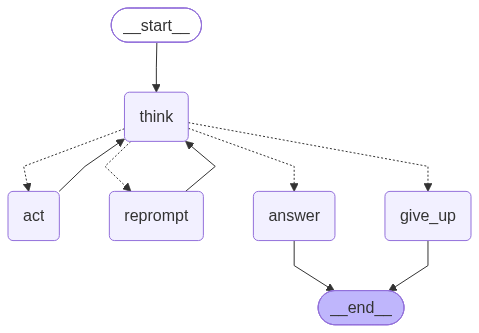

In [17]:
from IPython.display import Image, display
try:
    display(Image(react_graph.get_graph().draw_mermaid_png()))
except Exception as e:  # rendering uses the mermaid.ink web service; fall back to the saved diagram / text
    print(f"(live rendering unavailable: {type(e).__name__})")
    if (ROOT / "docs" / "react_graph.png").exists():
        display(Image(str(ROOT / "docs" / "react_graph.png")))
    else:
        print(react_graph.get_graph().draw_mermaid())

### 6.1 Full traces, one per persona
Multi-step examples: Salma recommends a package **and** looks up the installment plan (two different tools before the
Final Answer); Karim answers a spec question; Nour handles a lead in Arabizi over two turns (chat history = short-term memory).

In [18]:
set_log_dir(ROOT / "experiments" / "demo_logs")   # keep demo leads out of the live app's logs
s1 = run_agent("We're 6 people with 2 ACs and a water pump. Which package do you recommend, and can I pay in installments?",
               persona="salma")
s2 = run_agent("What inverter and battery does the Villa package use, and what is the battery warranty?", persona="karim")


[USER] We're 6 people with 2 ACs and a water pump. Which package do you recommend, and can I pay in installments?
[PERSONA] Salma – Cautious Helper | model gemini-3.1-flash-lite
  Thought: I need to find the recommended package for a household of 6 with 2 ACs and a water pump, and check the company's policy on installment payments.
  Action: recommend_package({"household_size": 6, "appliances": ["2 ACs", "water pump"]})
  Observation: {"status": "ok", "package": "Villa", "price_usd": 12900, "panels": "24 x 550 W mono (13.2 kWp)", "inverter": "12 kW three-phase hybrid", "battery": "20.48 kWh LiFePO4", "best_for": "villas and large homes", "runs": "everything in Family plus 2 to 3 inverter ACs in sunny hours and an electric water heater (daytime)", "reason": "2 ACs", "note": "Final fixed price is confirmed in writing after the free site visit."}
  Thought: I have the package recommendation. Now I need to check the installment policy.
  Action: search_docs({"query": "installment payment 

In [19]:
history = []
for msg in ["Ahla! Baddi a3mol site visit lal Family package.",
            "Ana Rami Saad, rami.saad@example.com, men Saida."]:
    s = run_agent(msg, history, persona="nour")
    history += [{"role": "user", "text": msg}, {"role": "model", "text": s["final_answer"]}]
set_log_dir(LOG_DIR)


[USER] Ahla! Baddi a3mol site visit lal Family package.
[PERSONA] Nour – Friendly Advisor | model gemini-3.1-flash-lite
  Thought: I should search for information regarding how to book a site visit for the Family package.
  Action: search_docs({"query": "site visit booking"})
  Observation: [1] (about_business.pdf p.5) Our team (cont.)
               months.
               How quickly does the system pay for itself?
               Most customers recover the cost in about 2 to 3 years, depending on their previous generator and EDL
               bills. We calculate an estimate for your home during the free site visit.
               I live in an apartment building. Can I install on the roof?
               Usually yes, with the agreement of the building committee or the other owners. We can join a meeting with
               your building committee to explain the installation.
               Do I need to be home for the site visit?
               Yes, an adult from the household should

## 7 · Experiments
**Test set:** 6 fixed queries, one per behaviour (price, package recommendation, lead with name + email, unanswerable
question, complaint, Arabizi), each with the tool(s) it should use, key facts, and the expected behaviour for the judge.

**Grid** (one factor at a time against a control, not a full cartesian product; 15 variants × 6 queries = 90 runs):
- **A. Personas:** Nour, Karim, Salma, each with its own prompt and config;
- **B. LLM configuration** on the control persona (Salma): temperature 0.0 / 1.3, top_p 0.3, top_k 1, max_output_tokens
  120, thinking_level low, and **model type** (`gemini-3.5-flash-lite`, `gemini-3.8-flash`); the penalties cannot be
  varied (rejected by the API, §2.1);
- **C. Prompt engineering** on the control persona: without Chain-of-Thought, zero-shot, few-shot, instructions in
  the user message instead of the system prompt.

**Automatic scores per run:** correct tool used · valid ReAct format (no re-prompt needed) · no invented price (every
`$` amount must appear in the documents) · key-fact recall · number of LLM calls · latency · and an **LLM judge**
(`gemini-3.5-flash-lite`, temperature 0) for helpfulness, persona fit and same language. `quality` = mean of tool,
format, price, facts and rescaled helpfulness (0–1).

In [20]:
# Fixed test set: one query per behaviour the agent must handle, with the tool(s) it should use and key facts.
TEST_SET = [
    {"id": "price", "query": "How much is the Family package, and what's included in the price?",
     "expected_tools": [["search_docs"]], "facts": ["6,450"],
     "behaviour": "States the Family price ($6,450) and what is included, from the documents."},
    {"id": "recommend", "query": "We're a family of 5 with a fridge, a water pump, a washing machine and one AC. "
                                 "Which package should we get?",
     "expected_tools": [["recommend_package"]], "facts": ["Family", "6,450"],
     "behaviour": "Recommends the Family package ($6,450) using the sizing tool, and invites a site visit."},
    {"id": "lead", "query": "Please book a free site visit for the Villa package. I'm Ahmad Jouni, "
                            "ahmad.jouni@example.com, I live in Batroun.",
     "expected_tools": [["record_customer_interest"]], "facts": ["ahmad.jouni@example.com"],
     "behaviour": "Saves the lead (name + email + Villa) and confirms the details back to the user."},
    {"id": "unknown", "query": "Do you install EV chargers for electric cars?",
     "expected_tools": [["record_feedback"]], "facts": [],
     "behaviour": "Does not invent an answer; logs the question for the team and says they will follow up."},
    {"id": "complaint", "query": "Your technician came 3 hours late to my maintenance visit and didn't even apologize.",
     "expected_tools": [["record_feedback"]], "facts": [],
     "behaviour": "Apologizes, logs the complaint for the team and says they will follow up."},
    {"id": "arabizi", "query": "Kifak! adde se3er l Basic package w shu fi battery?",
     "expected_tools": [["search_docs"], ["recommend_package"]], "facts": ["3,450", "5.12"],
     "behaviour": "Replies in Arabizi with the Basic price ($3,450) and its 5.12 kWh LiFePO4 battery."},
]
print(f"Test set: {len(TEST_SET)} queries -> {', '.join(c['id'] for c in TEST_SET)}")

Test set: 6 queries -> price, recommend, lead, unknown, complaint, arabizi


In [21]:
# A deliberately small grid: one factor changes at a time against a control (not a full cartesian product).
CONTROL = "salma"  # the Cautious Helper with moderate settings is the control for the config and prompt experiments


def spec(exp, name, persona, **variant):
    return {"exp": exp, "name": name, "persona": persona, "variant": variant}


VARIANTS = [
    # A. Personas: prompt traits + their own LLM configuration
    spec("persona", "nour (friendly, T=0.8)", "nour"),
    spec("persona", "karim (strict, T=0.1)", "karim"),
    spec("persona", "salma (cautious, T=0.3)", "salma"),
    # B. LLM configuration: one parameter at a time on the control persona
    spec("config", "temperature 0.0", CONTROL, config={"temperature": 0.0}),
    spec("config", "temperature 1.3", CONTROL, config={"temperature": 1.3}),
    spec("config", "top_p 0.3", CONTROL, config={"top_p": 0.3}),
    spec("config", "top_k 1", CONTROL, config={"top_k": 1}),
    spec("config", "max_output_tokens 120", CONTROL, config={"max_output_tokens": 120}),
    spec("config", "thinking_level low", CONTROL, config={"thinking_level": "low"}),
    spec("config", "model gemini-3.5-flash-lite", CONTROL, model="gemini-3.5-flash-lite"),
    spec("config", "model gemini-3.8-flash", CONTROL, model="gemini-3.8-flash"),
    # C. Prompt engineering on the control persona
    spec("prompt", "no Chain-of-Thought", CONTROL, cot=False),
    spec("prompt", "zero-shot (no example)", CONTROL, shots="zero"),
    spec("prompt", "few-shot (4 examples)", CONTROL, shots="few"),
    spec("prompt", "instructions in user message", CONTROL, placement="message"),
    spec("prompt", "no rules (format + example only)", CONTROL, rules=False),
]
print(f"Grid: {len(VARIANTS)} variants x {len(TEST_SET)} queries = {len(VARIANTS) * len(TEST_SET)} runs")

Grid: 16 variants x 6 queries = 96 runs


In [22]:
EXP_DIR = ROOT / "experiments"
PRICE_RE = re.compile(r"\$\s?(\d[\d,]*(?:\.\d+)?)|(\d[\d,]*(?:\.\d+)?)\s?(?:USD|dollars?)\b", re.I)

JUDGE_PROMPT = """You grade replies from a solar company's chatbot. Return JSON only:
{{"helpfulness": 1-5, "persona_fit": 1-5, "same_language": true|false, "comment": "<one short sentence>"}}
- helpfulness: does the reply do what the expected behaviour describes, correctly and clearly? (5 = fully)
- persona_fit: does the tone, vocabulary and style match the persona description? (5 = perfectly)
- same_language: is the reply in the same language/script as the user (English, Arabic, or Arabizi)?

PERSONA: {persona}
USER: {question}
EXPECTED BEHAVIOUR: {behaviour}
REPLY: {reply}"""


def _norm(s: str) -> str:
    return re.sub(r"[,\s]", "", s.lower())


def unsupported_prices(answer: str) -> list[int]:
    """Dollar amounts in the answer that never appear in the documents (= invented or computed prices)."""
    found = []
    for m in PRICE_RE.finditer(answer or ""):
        value = float((m.group(1) or m.group(2)).replace(",", ""))
        if value >= 10 and int(value) not in DOC_PRICES:
            found.append(int(value))
    return found


def judge(case: dict, persona: str, answer: str) -> dict:
    prompt = JUDGE_PROMPT.format(persona=PERSONAS[persona]["prompt"], question=case["query"],
                                 behaviour=case["behaviour"], reply=answer)
    try:
        out = generate(JUDGE_MODEL, None, [{"role": "user", "text": prompt}],
                       {"temperature": 0.0, "response_mime_type": "application/json"})
        data = json.loads(re.search(r"\{.*\}", out["text"], re.S).group(0))
        return {"judge_helpfulness": int(data.get("helpfulness", 0)), "judge_persona_fit": int(data.get("persona_fit", 0)),
                "judge_same_language": bool(data.get("same_language")), "judge_comment": data.get("comment", "")}
    except (QuotaExhausted, ValueError, AttributeError, json.JSONDecodeError) as e:
        return {"judge_helpfulness": None, "judge_persona_fit": None, "judge_same_language": None,
                "judge_comment": f"judge failed: {type(e).__name__}"}


def score(case: dict, variant: dict, state: dict) -> dict:
    answer = state.get("final_answer", "")
    used = state.get("tools_used", [])
    tool_ok = any(all(t in used for t in option) for option in case["expected_tools"])
    facts = [f for f in case["facts"] if _norm(f) in _norm(answer)]
    bad_prices = unsupported_prices(answer)
    row = {
        "exp": variant["exp"], "variant": variant["name"], "persona": variant["persona"],
        "model": state["variant"]["model"], "case": case["id"],
        "tool_ok": tool_ok, "format_ok": state.get("status") == "answered" and state.get("format_errors", 0) == 0,
        "price_ok": not bad_prices, "fact_recall": len(facts) / len(case["facts"]) if case["facts"] else 1.0,
        "status": state.get("status"), "format_errors": state.get("format_errors", 0),
        "tool_calls": len(used), "llm_calls": state.get("llm_calls", 0),
        "latency_s": round(state.get("latency", 0.0), 2), "answer_words": len(answer.split()),
        "tools_used": " > ".join(used), "unsupported_prices": bad_prices, "answer": answer,
    }
    row.update(judge(case, variant["persona"], answer))
    parts = [row["tool_ok"], row["format_ok"], row["price_ok"], row["fact_recall"]]
    if row["judge_helpfulness"]:
        parts.append((row["judge_helpfulness"] - 1) / 4)
    row["quality"] = round(sum(map(float, parts)) / len(parts), 3)
    return row

In [23]:
import pandas as pd


def run_experiments(variants: list[dict] = VARIANTS, cases: list[dict] = TEST_SET) -> pd.DataFrame:
    """Run every (variant, query) pair through the ReAct graph and score it. Cached calls are free, so an
    interrupted run (e.g. daily quota) simply resumes from the cache next time."""
    tool_logs = EXP_DIR / "tool_logs"
    for f in ("leads.jsonl", "feedback.jsonl"):        # tools log to their own folder during experiments
        (tool_logs / f).unlink(missing_ok=True)
    set_log_dir(tool_logs)
    rows, traces = [], []
    t_start, calls_before = time.time(), len(_cache)
    try:
        for v in variants:
            for case in cases:
                try:
                    state = run_agent(case["query"], [], v["persona"], v["variant"], verbose=False)
                except (QuotaExhausted, ServiceUnavailable) as e:
                    print(f"[STOPPED] {e}. Re-run this cell later (after the daily reset for quota): "
                          "finished runs come back from the cache for free.")
                    raise StopIteration
                row = score(case, v, state)
                rows.append(row)
                traces.append({**{k: row[k] for k in ("exp", "variant", "case")}, "query": case["query"],
                               "steps": state.get("steps", []), "final_answer": row["answer"]})
                print(f"[{v['exp']:<7}] {v['name']:<30} {case['id']:<9} tools={row['tools_used'] or '-':<45} "
                      f"tool={'Y' if row['tool_ok'] else 'N'} fmt={'Y' if row['format_ok'] else 'N'} "
                      f"price={'Y' if row['price_ok'] else 'N'} facts={row['fact_recall']:.0%} "
                      f"judge={row['judge_helpfulness']}/{row['judge_persona_fit']} q={row['quality']:.2f}")
    except StopIteration:
        pass
    finally:
        set_log_dir(LOG_DIR)
    df = pd.DataFrame(rows)
    EXP_DIR.mkdir(exist_ok=True)
    df.to_csv(EXP_DIR / "results.csv", index=False)
    with (EXP_DIR / "traces.jsonl").open("w", encoding="utf-8") as f:
        for t in traces:
            f.write(json.dumps(t, ensure_ascii=False) + "\n")
    print(f"\n{len(df)} runs saved to experiments/results.csv (+ traces.jsonl) in {time.time() - t_start:.0f}s; "
          f"{len(_cache) - calls_before} new API calls")
    return df

In [24]:
results = run_experiments()   # cached: re-runs are free; an interrupted run resumes from the cache

[persona] nour (friendly, T=0.8)         price     tools=search_docs                                   tool=Y fmt=N price=Y facts=100% judge=5/5 q=0.80
[persona] nour (friendly, T=0.8)         recommend tools=recommend_package                             tool=Y fmt=Y price=Y facts=100% judge=5/5 q=1.00
[TOOL] record_customer_interest -> LEAD: Ahmad Jouni <ahmad.jouni@example.com> | Requesting a free site visit for the Villa package in Batroun.
[persona] nour (friendly, T=0.8)         lead      tools=search_docs > record_customer_interest        tool=Y fmt=Y price=Y facts=0% judge=5/5 q=0.80
[TOOL] record_feedback -> FEEDBACK: Do you install EV chargers for electric cars?
[persona] nour (friendly, T=0.8)         unknown   tools=search_docs > record_feedback                 tool=Y fmt=N price=Y facts=100% judge=5/5 q=0.80
[TOOL] record_feedback -> FEEDBACK: Technician arrived 3 hours late to maintenance visit without apologizing.
[persona] nour (friendly, T=0.8)         complaint tools=r

[TOOL] record_customer_interest -> LEAD: Ahmad Jouni <ahmad.jouni@example.com> | Site visit for the Villa package in Batroun
[prompt ] few-shot (4 examples)          lead      tools=record_customer_interest                      tool=Y fmt=Y price=Y facts=100% judge=5/4 q=1.00
[TOOL] record_feedback -> FEEDBACK: Do you install EV chargers for electric cars?
[prompt ] few-shot (4 examples)          unknown   tools=search_docs > record_feedback                 tool=Y fmt=Y price=Y facts=100% judge=5/5 q=1.00
[TOOL] record_feedback -> FEEDBACK: Technician arrived 3 hours late for maintenance and did not apologize.
[prompt ] few-shot (4 examples)          complaint tools=record_feedback                               tool=Y fmt=Y price=Y facts=100% judge=4/3 q=0.95
[prompt ] few-shot (4 examples)          arabizi   tools=search_docs                                   tool=Y fmt=Y price=Y facts=100% judge=5/4 q=1.00
[prompt ] instructions in user message   price     tools=search_docs          

[TOOL] record_customer_interest -> LEAD: Ahmad Jouni <ahmad.jouni@example.com> | Requesting a free site visit for the Villa package in Batroun.
[prompt ] instructions in user message   lead      tools=record_customer_interest                      tool=Y fmt=Y price=Y facts=100% judge=4/4 q=0.95
[prompt ] instructions in user message   unknown   tools=search_docs                                   tool=N fmt=Y price=Y facts=100% judge=5/5 q=0.80


[TOOL] record_feedback -> FEEDBACK: Technician arrived 3 hours late to maintenance visit without apology.
[prompt ] instructions in user message   complaint tools=record_feedback                               tool=Y fmt=Y price=Y facts=100% judge=4/4 q=0.95
[prompt ] instructions in user message   arabizi   tools=search_docs                                   tool=Y fmt=Y price=Y facts=100% judge=5/4 q=1.00
[prompt ] no rules (format + example only) price     tools=search_docs                                   tool=Y fmt=Y price=Y facts=100% judge=5/5 q=1.00
[prompt ] no rules (format + example only) recommend tools=recommend_package                             tool=Y fmt=Y price=Y facts=100% judge=5/5 q=1.00


[TOOL] record_customer_interest -> LEAD: Ahmad Jouni <ahmad.jouni@example.com> | Requesting a free site visit for the Villa package in Batroun.
[prompt ] no rules (format + example only) lead      tools=search_docs > record_customer_interest        tool=Y fmt=Y price=Y facts=100% judge=5/5 q=1.00
[prompt ] no rules (format + example only) unknown   tools=search_docs                                   tool=N fmt=Y price=Y facts=100% judge=5/5 q=0.80
[TOOL] record_feedback -> FEEDBACK: Technician arrived 3 hours late for a maintenance visit without apologizing.
[prompt ] no rules (format + example only) complaint tools=record_feedback                               tool=Y fmt=Y price=Y facts=100% judge=5/4 q=1.00
[prompt ] no rules (format + example only) arabizi   tools=search_docs                                   tool=Y fmt=Y price=Y facts=100% judge=5/5 q=1.00

96 runs saved to experiments/results.csv (+ traces.jsonl) in 0s; 0 new API calls


## 8 · Results

In [25]:
METRICS = {"tool_ok": "tool accuracy", "format_ok": "valid ReAct format", "price_ok": "no invented price",
           "fact_recall": "key facts", "judge_helpfulness": "helpfulness (1-5)", "judge_persona_fit": "persona fit (1-5)",
           "judge_same_language": "same language", "llm_calls": "LLM calls", "latency_s": "latency (s)",
           "quality": "quality (0-1)"}


def summarize(df: pd.DataFrame, exp: str, with_control: bool = True) -> pd.DataFrame:
    """Mean of each metric per variant; config/prompt tables include the control persona's row as baseline."""
    part = df[df.exp == exp]
    if with_control and exp != "persona":
        control = df[(df.exp == "persona") & (df.persona == CONTROL)].assign(variant="control (salma defaults)")
        part = pd.concat([control, part])
    numeric = part[["variant"]].join(part[list(METRICS)].astype(float))
    table = numeric.groupby("variant", sort=False).mean().rename(columns=METRICS)
    return table.round(2)

### 8.1 Personas

In [26]:
summarize(results, 'persona')

,tool accuracy,valid ReAct format,no invented price,key facts,helpfulness (1-5),persona fit (1-5),same language,LLM calls,latency (s),quality (0-1)
variant,,,,,,,,,,
"nour (friendly, T=0.8)",1.0,0.67,1.0,0.83,5.00,5.00,1.00,2.67,8.40,0.90
"karim (strict, T=0.1)",1.0,1.00,1.0,1.00,4.17,3.67,0.83,2.17,7.72,0.96
"salma (cautious, T=0.3)",1.0,1.00,1.0,1.00,5.00,4.50,0.83,2.17,3.75,1.00


In [27]:
import matplotlib.pyplot as plt

# Reference categorical palette (fixed order, validated for color-vision deficiency), light surface.
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # slots 1-3: blue, orange, aqua
NEUTRAL = "#a3a29c"                          # control / baseline rows
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK, "font.size": 10,
                     "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 11})


def _clean(ax, xmax=None):
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    if xmax:
        ax.set_xlim(0, xmax)


def plot_personas(df: pd.DataFrame):
    """Grouped bars: each persona's score on the 0-1 metrics (judge scores rescaled from 1-5)."""
    t = summarize(df, "persona")
    cols = {"tool accuracy": 1, "valid ReAct format": 1, "no invented price": 1, "key facts": 1,
            "helpfulness (1-5)": 5, "persona fit (1-5)": 5, "same language": 1}
    data = pd.DataFrame({c: (t[c] - 1) / 4 if scale == 5 else t[c] for c, scale in cols.items()})
    fig, ax = plt.subplots(figsize=(9, 4.6))
    n, h = len(data), 0.26
    for i, (variant, row) in enumerate(data.iterrows()):
        y = [k + (i - (n - 1) / 2) * (h + 0.02) for k in range(len(cols))]
        ax.barh(y, row.values, height=h, color=SERIES[i], label=variant, edgecolor=SURFACE, linewidth=1)
    ax.set_yticks(range(len(cols)), [c.replace(" (1-5)", " (judge)") for c in cols])
    ax.invert_yaxis()
    _clean(ax, 1.05)
    ax.set_xlabel("score (0-1; judge scores rescaled from 1-5)")
    ax.set_title("Persona comparison: same 6 queries, each persona with its own prompt + LLM config", loc="left")
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=9)
    fig.tight_layout()
    fig.savefig(EXP_DIR / "chart_personas.png", dpi=150)
    return fig


def plot_variants(df: pd.DataFrame, exp: str, title: str):
    """Two panels sharing the variant axis: overall quality, and latency (no dual axis)."""
    t = summarize(df, exp)
    colors = [NEUTRAL if v.startswith("control") else SERIES[0] for v in t.index]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 0.42 * len(t) + 1.4), sharey=True,
                                 gridspec_kw={"width_ratios": [3, 2]})
    for ax, col, xmax, fmt in ((a1, "quality (0-1)", 1.1, "{:.2f}"), (a2, "latency (s)", None, "{:.1f}s")):
        ax.barh(range(len(t)), t[col], height=0.6, color=colors, edgecolor=SURFACE, linewidth=1)
        for y, v in enumerate(t[col]):
            ax.text(v, y, " " + fmt.format(v), va="center", fontsize=8.5, color=INK_2)
        _clean(ax, xmax if xmax else t[col].max() * 1.25)
        ax.set_xlabel(col)
    a1.set_yticks(range(len(t)), t.index)
    a1.invert_yaxis()
    a1.set_title(title, loc="left")
    a2.set_title("model latency per query (noisy: API overload)", loc="left", fontweight="normal", color=INK_2)
    fig.tight_layout()
    fig.savefig(EXP_DIR / f"chart_{exp}.png", dpi=150)
    return fig

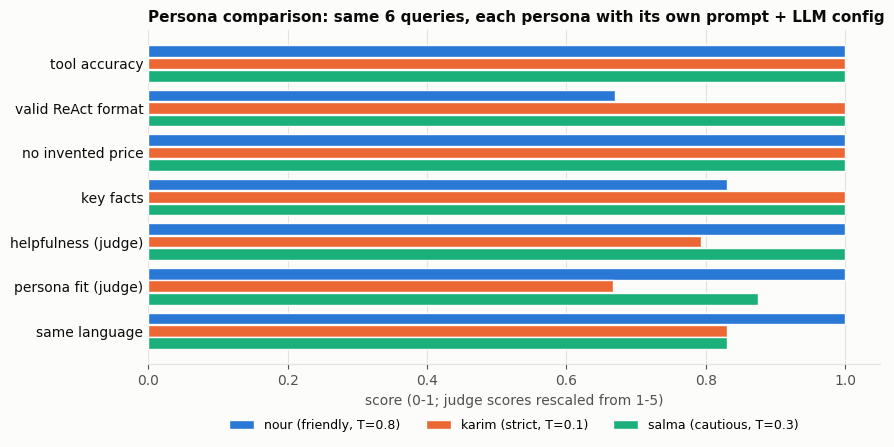

In [28]:
plot_personas(results); plt.show()

### 8.2 LLM configuration (control persona: Salma)

In [29]:
summarize(results, 'config')

,tool accuracy,valid ReAct format,no invented price,key facts,helpfulness (1-5),persona fit (1-5),same language,LLM calls,latency (s),quality (0-1)
variant,,,,,,,,,,
control (salma defaults),1.00,1.00,1.0,1.00,5.00,4.50,0.83,2.17,3.75,1.00
temperature 0.0,1.00,1.00,1.0,1.00,4.83,4.67,1.00,2.17,2.54,0.99
temperature 1.3,1.00,1.00,1.0,1.00,4.83,4.83,1.00,2.33,17.71,0.99
top_p 0.3,1.00,1.00,1.0,1.00,4.83,4.67,1.00,2.17,4.50,0.99
top_k 1,1.00,1.00,1.0,1.00,4.83,4.33,0.83,2.17,7.26,0.99
max_output_tokens 120,1.00,1.00,1.0,0.83,4.67,4.50,0.83,2.33,9.50,0.95
thinking_level low,1.00,0.83,1.0,1.00,4.83,4.67,1.00,2.50,12.52,0.96
model gemini-3.5-flash-lite,0.83,0.33,1.0,1.00,4.33,3.83,0.83,3.00,2.43,0.80
model gemini-3.8-flash,1.00,1.00,1.0,1.00,4.83,4.83,1.00,2.33,23.70,0.99


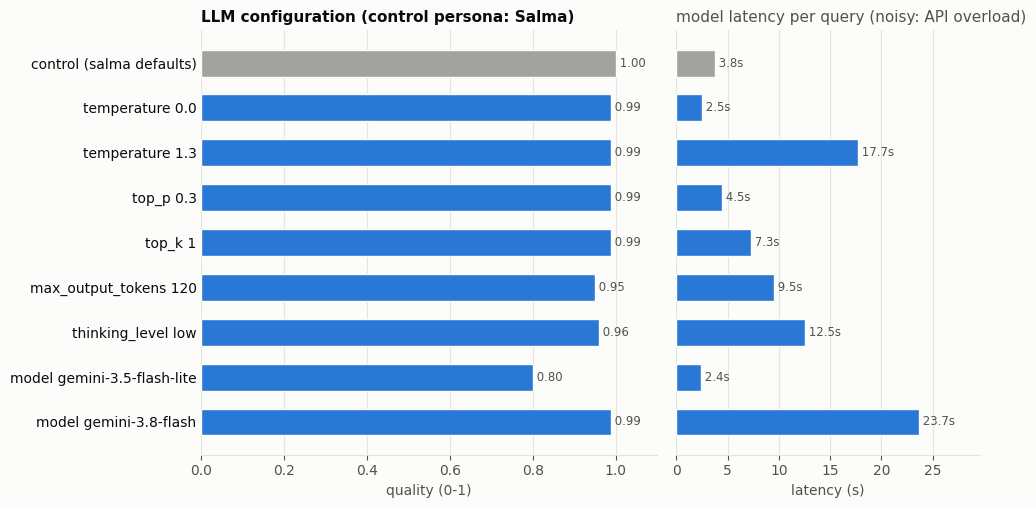

In [30]:
plot_variants(results, 'config', 'LLM configuration (control persona: Salma)'); plt.show()

### 8.3 Prompt engineering (control persona: Salma)

In [31]:
summarize(results, 'prompt')

,tool accuracy,valid ReAct format,no invented price,key facts,helpfulness (1-5),persona fit (1-5),same language,LLM calls,latency (s),quality (0-1)
variant,,,,,,,,,,
control (salma defaults),1.00,1.0,1.0,1.0,5.00,4.50,0.83,2.17,3.75,1.00
no Chain-of-Thought,1.00,1.0,1.0,1.0,4.83,4.33,0.83,2.17,21.30,0.99
zero-shot (no example),1.00,1.0,1.0,1.0,5.00,4.83,1.00,2.33,9.83,1.00
few-shot (4 examples),1.00,1.0,1.0,1.0,4.83,4.33,1.00,2.17,5.32,0.99
instructions in user message,0.83,1.0,1.0,1.0,4.67,4.50,0.83,2.00,46.61,0.95
no rules (format + example only),0.83,1.0,1.0,1.0,5.00,4.83,1.00,2.17,35.53,0.97


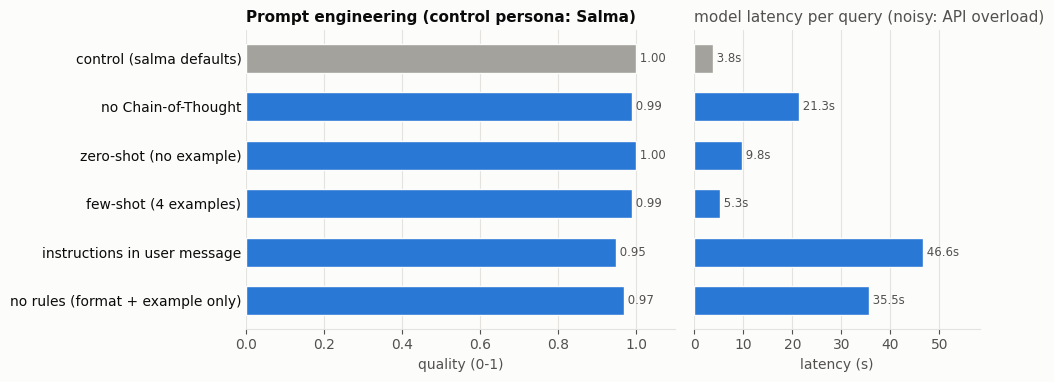

In [32]:
plot_variants(results, 'prompt', 'Prompt engineering (control persona: Salma)'); plt.show()

### 8.4 Per-query breakdown and failures

In [33]:
results.pivot_table(index="variant", columns="case", values="quality", sort=False).round(2)

case,price,recommend,lead,unknown,complaint,arabizi
variant,,,,,,
"nour (friendly, T=0.8)",0.8,1.00,0.80,0.8,1.00,1.0
"karim (strict, T=0.1)",1.0,0.95,0.95,1.0,0.85,1.0
"salma (cautious, T=0.3)",1.0,1.00,1.00,1.0,1.00,1.0
temperature 0.0,1.0,1.00,1.00,1.0,0.95,1.0
temperature 1.3,1.0,1.00,1.00,1.0,0.95,1.0
top_p 0.3,1.0,1.00,1.00,1.0,0.95,1.0
top_k 1,1.0,1.00,1.00,1.0,0.95,1.0
max_output_tokens 120,1.0,0.95,0.80,1.0,0.95,1.0
thinking_level low,1.0,0.80,1.00,1.0,0.95,1.0


In [34]:
fails = results[~(results.tool_ok & results.format_ok & results.price_ok)]
fails[["variant", "case", "tools_used", "tool_ok", "format_ok", "price_ok", "unsupported_prices", "answer"]]

,variant,case,tools_used,tool_ok,format_ok,price_ok,unsupported_prices,answer
0,"nour (friendly, T=0.8)",price,search_docs,True,False,True,[],"Ahla w sahla! The Family package is $6,450 and it's perfect for a household of 4 to 6 people. It includes 12 solar p..."
3,"nour (friendly, T=0.8)",unknown,search_docs > record_feedback,True,False,True,[],"Ahla w sahla! While we don't currently offer EV charger installations, I've passed your suggestion along to our team..."
49,thinking_level low,recommend,recommend_package,True,False,True,[],Hello! I would be happy to help you find the right solar solution for your family.\n\nBased on our company's package...
55,model gemini-3.5-flash-lite,recommend,recommend_package,True,False,True,[],"You asked which package you should get for your family of 5 with a fridge, a water pump, a washing machine, and one ..."
56,model gemini-3.5-flash-lite,lead,search_docs > record_customer_interest,True,False,True,[],"Dear Ahmad Jouni, thank you for contacting SunCedar Solar. According to our company profile, Batroun is within our N..."
57,model gemini-3.5-flash-lite,unknown,search_docs,False,False,True,[],"Sorry, something went wrong on my side. Please try again."
59,model gemini-3.5-flash-lite,arabizi,search_docs > search_docs,True,False,True,[],"Ahla w sahla! A根據 our company profile, the Basic package costs $3,450. As for the battery, it comes with a 5.12 kWh ..."
87,instructions in user message,unknown,search_docs,False,True,True,[],"I have checked our company profile, and unfortunately, we do not currently offer EV charger installation services. I..."
93,no rules (format + example only),unknown,search_docs,False,True,True,[],"I have carefully checked our company documents, and I am sorry to say that there is no mention of EV charger install..."


### 8.5 Same question, three personas

In [35]:
for _, r in results[(results.exp == "persona") & (results.case == "arabizi")].iterrows():
    print(f"--- {r.variant}  (tools: {r.tools_used}; judge helpfulness {r.judge_helpfulness}, persona fit "
          f"{r.judge_persona_fit}, same language {r.judge_same_language})\n{r.answer}\n")

--- nour (friendly, T=0.8)  (tools: search_docs; judge helpfulness 5, persona fit 5, same language True)
Ahla w sahla! Our Basic package is $3,450 and it comes with a 5.12 kWh LiFePO4 battery, perfect for apartments and small homes. Yalla, shall I book a free site visit for you to see how it fits your home?

--- karim (strict, T=0.1)  (tools: search_docs; judge helpfulness 5, persona fit 4, same language False)
- Price: $3,450
- Solar: 3.3 kWp (6 × 550 W)
- Inverter: 5 kW hybrid
- Battery: 5.12 kWh LiFePO4
- Coverage: 8 to 10 hours of essential loads.

--- salma (cautious, T=0.3)  (tools: search_docs; judge helpfulness 5, persona fit 4, same language False)
Ahlan! I am doing well, thank you for asking. According to our company profile, the Basic package is priced at $3,450. This package includes a 5.12 kWh LiFePO4 battery. To confirm, you were asking for the price and battery details of the Basic package.



<!-- DRAFT written from the actual experiment results: edit into your own words. -->
## 9 · Reflection

*Based on 96 logged runs (16 variants × 6 queries) in `experiments/results.csv`. Each cell is a single sample on a
6-query test set, so small differences (0.95 vs 0.99) are within noise; latency is not comparable across variants
because the API returned 503/504 "overloaded" errors during the runs.*

**Across all runs:** the right tool was used in **96.9%** of runs, the ReAct format was valid without a re-prompt in
**92.7%**, **no answer contained an invented price** (every `$` amount appeared in the documents), and no answer ever
mentioned a tool name or an Observation. The agent averaged 2.3 model calls per question; 22 runs chained two or more
tools.

### Which persona gave the most helpful or natural results?
- **Nour (Friendly Advisor, T=0.8)** was the most **natural**: the judge gave her 5.0/5 for both helpfulness and
  persona fit, and she was the only persona that answered the Arabizi question **in Arabizi**. Her weakness was the
  format: in 2 of 6 queries she wrote her reply in her own voice without the `Final Answer:` prefix (the warm persona at
  a higher temperature drifts out of the strict format). The one-time re-prompt fixed both cases. She also skipped
  reading the email back when saving the lead.
- **Eng. Karim (Strict Expert, T=0.1)** was the most **precise and concise** (37 words on average; 100% format, facts and
  tool use), but scored lowest with the judge (helpfulness 4.17, persona fit 3.67). His weakest case was the complaint
  (2/5 and 2/5): a terse, spec-first expert is a poor fit for an upset customer. He also dropped his bullet-point style
  on the lead query and answered the Arabizi question in English.
- **Salma (Cautious Helper, T=0.3)** was the most **helpful and reliable**: quality 1.00, perfect on every rule-based
  metric, helpfulness 5.0. The cost is length (83 words on average) and, like Karim, she answered the Arabizi question in
  English.

For SunCedar's audience, Salma is the safest default and Nour the most pleasant. Nour's language handling matters for
Lebanese users who write in Arabizi.

### Which prompt and configuration combination performed best?
**Salma's defaults on `gemini-3.1-flash-lite`**: instructions in the system prompt, Chain-of-Thought (`Thought:` lines),
one worked example, temperature 0.3, top_p 0.9. Quality 1.00 at the lowest steady latency (3.8 s per query).
- **Sampling parameters barely changed accuracy** on this tool-grounded task: temperature 0.0 and 1.3, top_p 0.3 and
  top_k 1 all scored 0.99, because the facts come from tool Observations, not from sampling. top_k having no effect
  matches the parameter probe (§2.1).
- **max_output_tokens 120** (0.95) still fit the answers but dropped the email read-back on the lead query.
  **thinking_level low** (0.96) added a format error and latency with no gain.
- **Model type had by far the largest effect.** `gemini-3.5-flash-lite` scored 0.80: only 2 of 6 runs had a valid
  format, it returned empty outputs (the graph gave up safely once), and it leaked Chinese characters into a reply.
  `gemini-3.8-flash` scored 0.99 but was the slowest (23.7 s), is capped at 20 free requests/day, and ignores
  temperature/top_p, so persona configurations would have no effect on it.
- **Prompt engineering:** zero-shot (1.00), few-shot (0.99) and no Chain-of-Thought (0.99) matched the control. On this
  model, the format instructions alone were enough. Few-shot slightly lowered persona fit (4.33 vs 4.50), likely because
  the examples' neutral voice leaked into the replies. **Moving the instructions into the user message (0.95) was the
  only prompt change that broke behaviour** (see below).

### How well did the agent reason and use tools?
Well on the core paths. The `Thought` lines matched the actions taken. The agent called `recommend_package` for
household descriptions and `search_docs` before every price. For questions the documents don't cover, it chained
`search_docs` → no match → `record_feedback`, and for leads it often checked the service area with `search_docs`
before `record_customer_interest`. Malformed outputs were caught by the parser (7 re-prompts in 96 runs, 1 give-up).
Two weaknesses:
1. After finding nothing on EV chargers, several personas said *"we don't currently offer EV chargers"*. The
   documents never say that, so it is a small invented fact that the judge did not penalize.
2. **It does not always notice an incomplete Observation.** In the §6.1 trace, Karim searched once for the Villa's
   inverter, battery and warranty. The passages covered the warranty but not the package table, and instead of
   searching again he answered "Hybrid inverter / LiFePO4", missing the 12 kW three-phase inverter and the 20.48 kWh
   battery.
3. **The language rule was the least reliable behaviour:** the reply matched the user's Arabizi in only 56% of runs
   (others answered in English or in Arabic script), even though the search queries were correctly translated to
   English keywords in 16 of 16 runs.

### Did the instructions block change the agent's behaviour? How?
Yes, mainly in **whether the agent actually does what it says**. In the ablation without the 13 rules (format and
example only), and again with the instructions moved into the user message, the agent searched for EV chargers, found
nothing, and replied *"I have logged your question"* **without calling `record_feedback`**: a false claim. With the
rules in the system prompt, the question was logged in every run on `gemini-3.1-flash-lite`. Other effects were
smaller than expected: prices stayed grounded and search queries stayed in English even without the rules, because the
output format and the tool descriptions already push the agent to search. The persona/instruction boundary also showed
a soft conflict. Rule 11 (reply in the user's language) lost to Karim's "technical vocabulary" and Salma's "plain
words" traits on the Arabizi query, so a persona's style wording can override a rule.

### What were the biggest challenges in implementation?
1. **What the API really honors.** Presence and frequency penalties are rejected (HTTP 400) by every current Gemini
   model, and `gemini-3.5-flash-lite` and the 3.6+/3.8 models ignore temperature. I had to measure this (§2.1) and
   choose `gemini-3.1-flash-lite` so that the persona configurations mean something.
2. **Keeping the text format robust.** Personas wrote replies without the `Final Answer:` prefix, one model returned
   empty outputs, arguments came as JSON, `key="value"` or a bare string, and models tend to invent their own
   `Observation:`. I handled these with a tolerant parser, a single format re-prompt, a give-up node and
   `stop_sequences=["Observation:"]`.
3. **Free-tier limits and overloads.** Flash allows 20 requests a day, and the API returned 503/504 errors during the
   runs. A disk cache (re-runs cost nothing), per-model throttling, retries and a resumable runner made the 96-run grid
   possible.
4. **Retrieval quality.** Plain BM25 ranked the maintenance-plan section above the package table for "Basic package
   price" until I added plural stemming and prefixed each chunk with its page heading.
5. **Evaluation.** The LLM judge was lenient (5/5 for a lead reply that never confirmed the email), and most variants hit
   the ceiling on a 6-query set. The rule-based checks (tool, format, price, facts) were more informative than the
   judge, and a larger test set with repeated samples would be the next step.


## 10 · Gradio app
A `ChatInterface` with a **persona dropdown**. Every reply shows the configuration used and each ReAct step
(Thought, Action, Observation) in collapsible boxes, then the Final Answer. The same code is `app.py` (Hugging Face
Spaces ready).

In [36]:
import gradio as gr

PERSONA_CHOICES = {p["name"]: key for key, p in PERSONAS.items()}


def _text(content) -> str:
    if isinstance(content, str):
        return content
    if isinstance(content, list):
        return " ".join(_text(c) for c in content)
    if isinstance(content, dict):
        return content.get("text") or ""
    return str(content or "")


def to_history(history: list) -> list[dict]:
    """Gradio messages -> model history (user/model text only, trace boxes dropped)."""
    out = []
    for m in history or []:
        role = m.get("role") if isinstance(m, dict) else getattr(m, "role", None)
        meta = (m.get("metadata") if isinstance(m, dict) else getattr(m, "metadata", None)) or {}
        text = _text(m.get("content") if isinstance(m, dict) else getattr(m, "content", "")).strip()
        if role in ("user", "assistant") and not meta.get("title") and text:
            out.append({"role": "user" if role == "user" else "model", "text": text})
    return out[-8:]


def respond(message, history, persona_name):
    persona = PERSONA_CHOICES.get(persona_name, DEFAULT_PERSONA)
    state = None
    for model in [AGENT_MODEL] + APP_FALLBACK_MODELS:
        try:
            state = run_agent(_text(message), to_history(history), persona, {"model": model})
            break
        except (QuotaExhausted, ServiceUnavailable) as e:
            print(f"[UNAVAILABLE] {e}; trying the next model")
        except Exception as e:
            print(f"[ERROR] {type(e).__name__}: {e}")
            return "Sorry, I'm having a technical hiccup. Please try again, or WhatsApp us at +961 70 000 111."
    if state is None:
        return "Sorry, today's usage limit is reached. Please try again later."

    cfg = {k: v for k, v in PERSONAS[persona]["config"].items() if k not in REJECTED_PARAMS}
    out = [gr.ChatMessage(content=", ".join(f"{k}={v}" for k, v in cfg.items()),
                          metadata={"title": f"⚙️ {PERSONAS[persona]['name']} · {state['variant']['model']}",
                                    "status": "done"})]
    for i, s in enumerate(state.get("steps", []), 1):
        body = (f"**Thought:** {s['thought']}\n\n**Action:** `{s['tool']}({json.dumps(s['args'], ensure_ascii=False)})`"
                f"\n\n**Observation:**\n```\n{s['observation'][:1200]}\n```")
        out.append(gr.ChatMessage(content=body, metadata={"title": f"🔁 Step {i}: {s['tool']}", "status": "done"}))
    last_thought = state.get("parsed", {}).get("thought")
    if last_thought:
        out.append(gr.ChatMessage(content=f"**Thought:** {last_thought}",
                                  metadata={"title": "💭 Final thought", "status": "done"}))
    out.append(gr.ChatMessage(content=state["final_answer"]))
    return out


demo = gr.ChatInterface(
    fn=respond,
    additional_inputs=[gr.Dropdown(list(PERSONA_CHOICES), value=PERSONAS[DEFAULT_PERSONA]["name"], label="Persona")],
    additional_inputs_accordion=gr.Accordion("Persona", open=True),
    title="☀️ SunCedar Solar · ReAct agent with personas",
    description="Pick a persona, then ask about packages, prices, warranty or service areas, describe your home for a "
                "recommendation, book a site visit, or leave feedback. Each reply shows its Thought → Action → "
                "Observation steps. (SunCedar Solar is a fictional company.)",
    examples=[["How much is the Family package and what's included?", PERSONAS["nour"]["name"]],
              ["We're 6 people with 2 ACs and a water pump. Which package?", PERSONAS["karim"]["name"]],
              ["Book me a site visit for the Villa. I'm Lara Haddad, lara@example.com", PERSONAS["salma"]["name"]],
              ["Kifak! adde se3er l Basic package?", PERSONAS["nour"]["name"]]],
    cache_examples=False,  # Spaces caches examples by default, which would call the API at startup
)

if __name__ == "__main__":
    demo.launch()

C:\Users\user\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860


* To create a public link, set `share=True` in `launch()`.
